In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('/content/Crop_recommendation.csv')
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
print("Shape:", df.shape)
df.info()

Shape: (2200, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [5]:
df.describe().round(2)

,N,P,K,temperature,humidity,ph,rainfall
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56


In [6]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0


Number of crops: 22
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


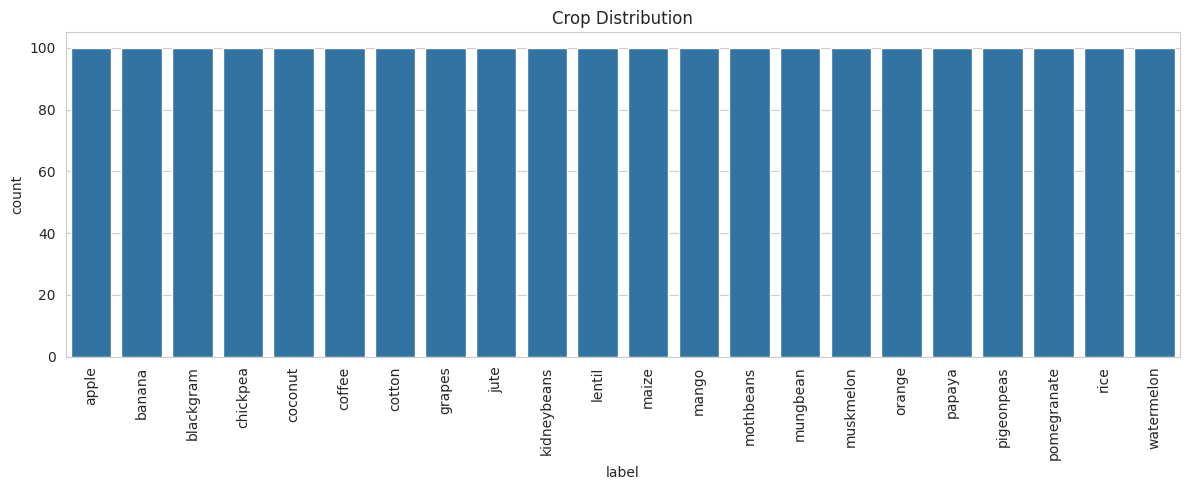

In [7]:
print("Number of crops:", df['label'].nunique())
print(df['label'].value_counts())

plt.figure(figsize=(12,5))
sns.countplot(data=df, x='label', order=sorted(df['label'].unique()))
plt.xticks(rotation=90); plt.title('Crop Distribution')
plt.tight_layout(); plt.show()

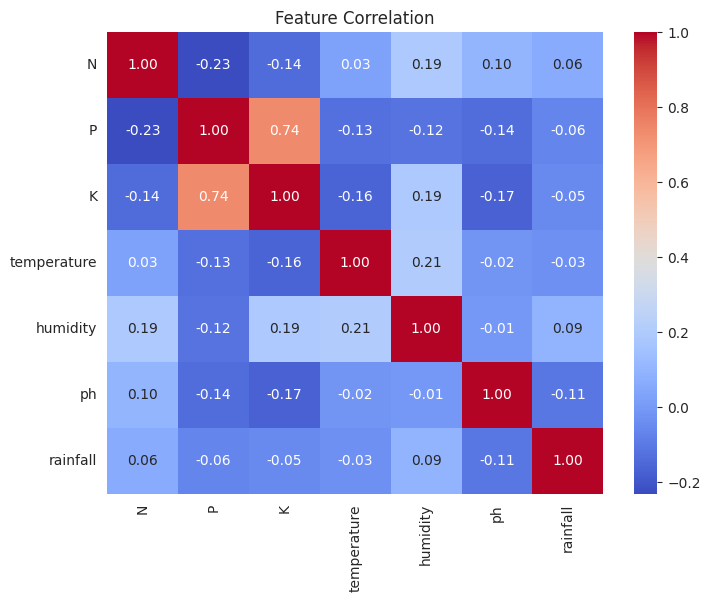

In [8]:
features = ['N','P','K','temperature','humidity','ph','rainfall']

plt.figure(figsize=(8,6))
sns.heatmap(df[features].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation'); plt.show()

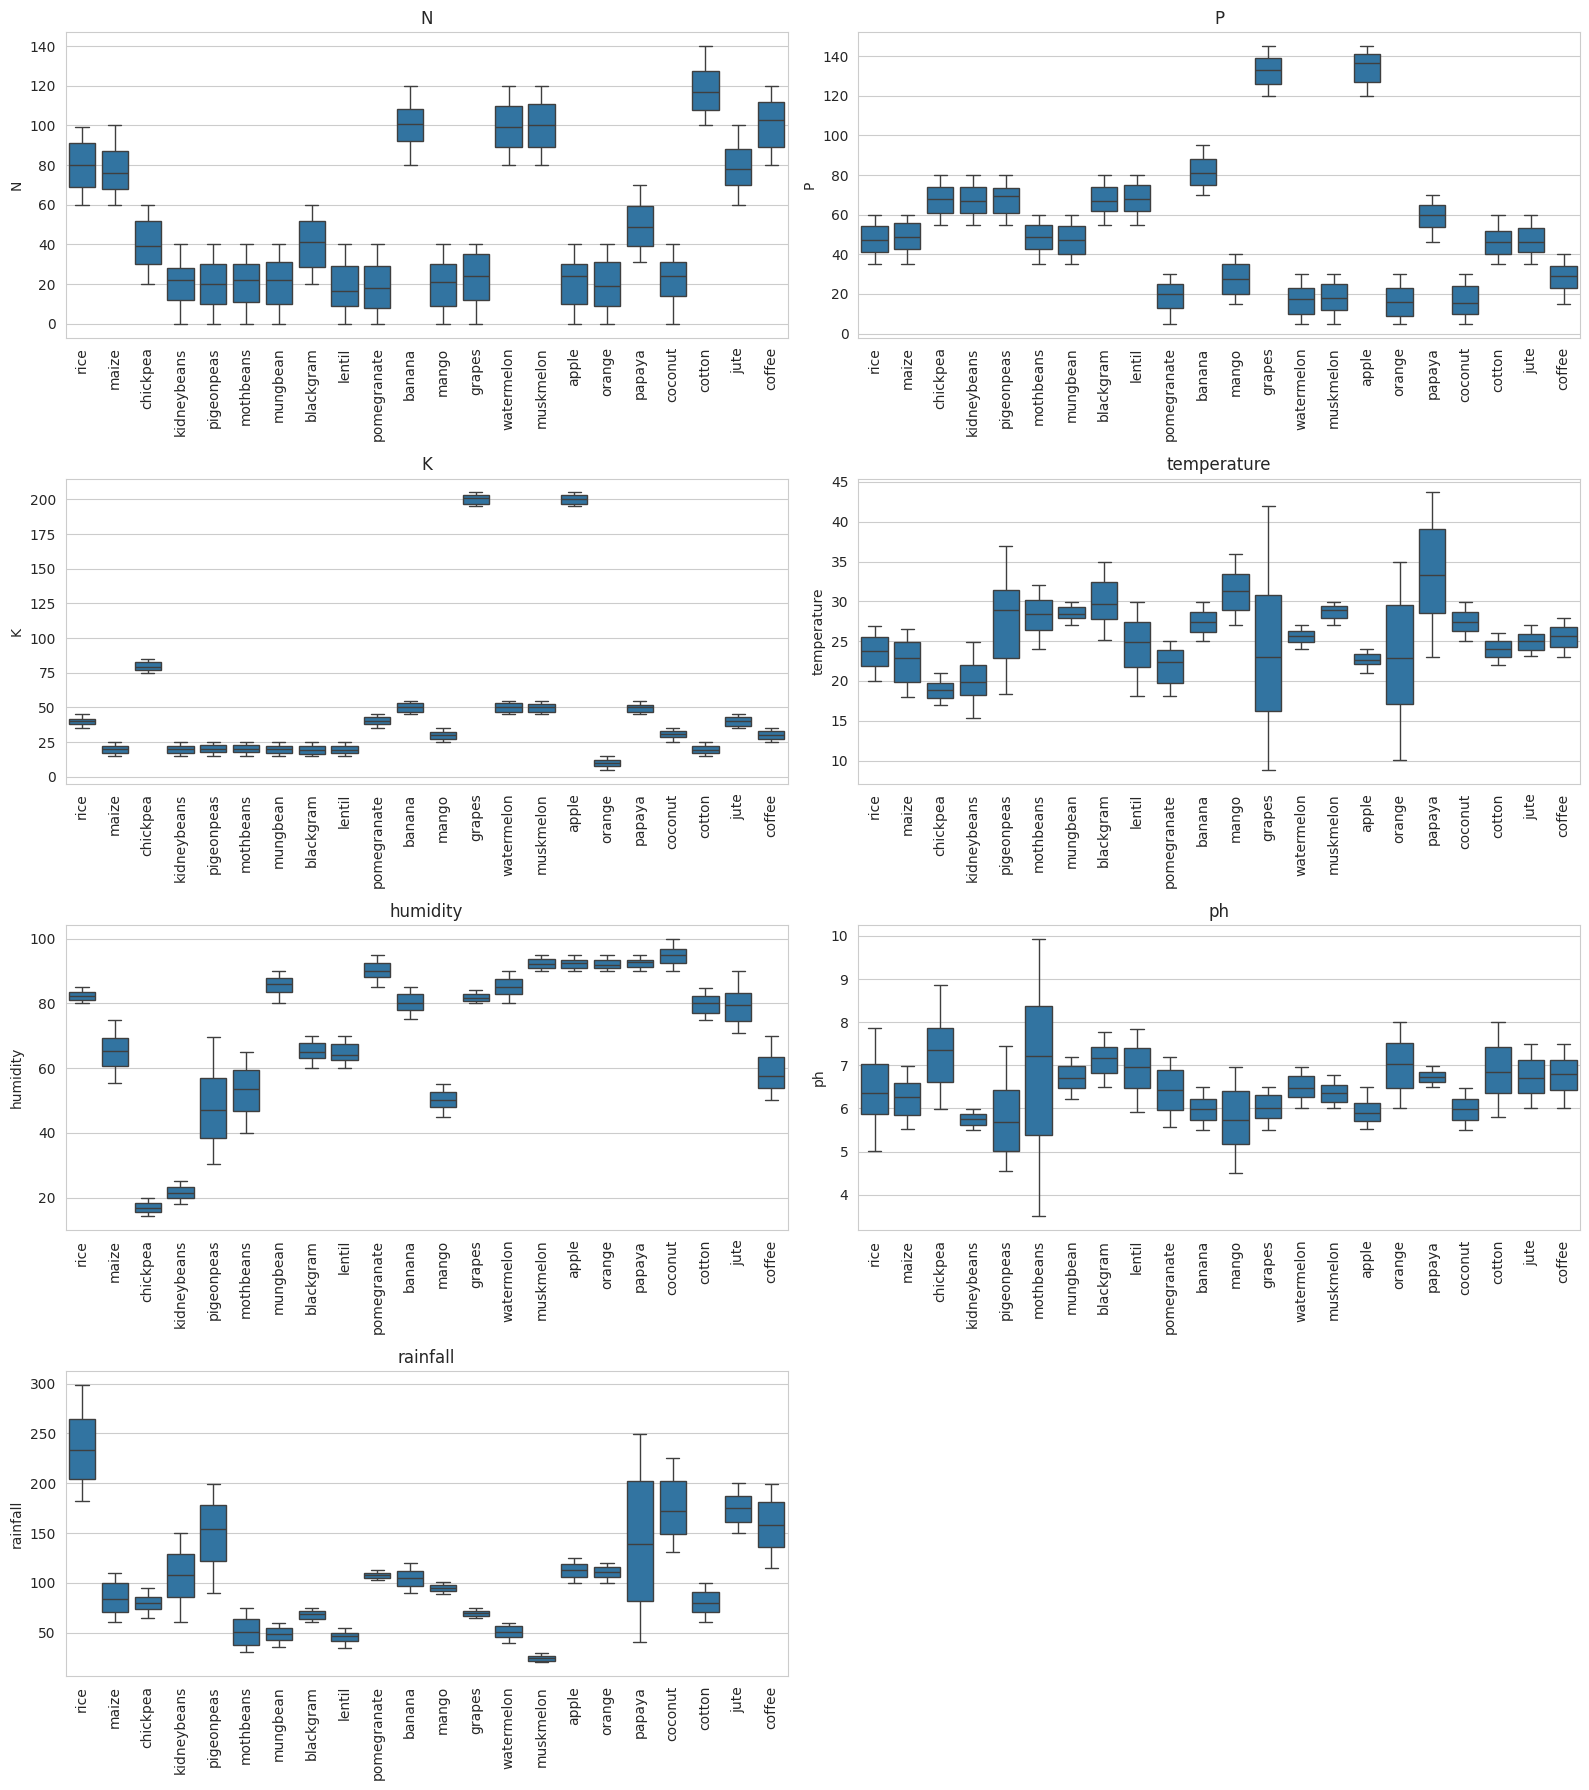

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(16, 18))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(data=df, x='label', y=col, ax=ax)
    ax.set_title(col); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=90)
axes.flatten()[-1].axis('off')
plt.tight_layout(); plt.show()

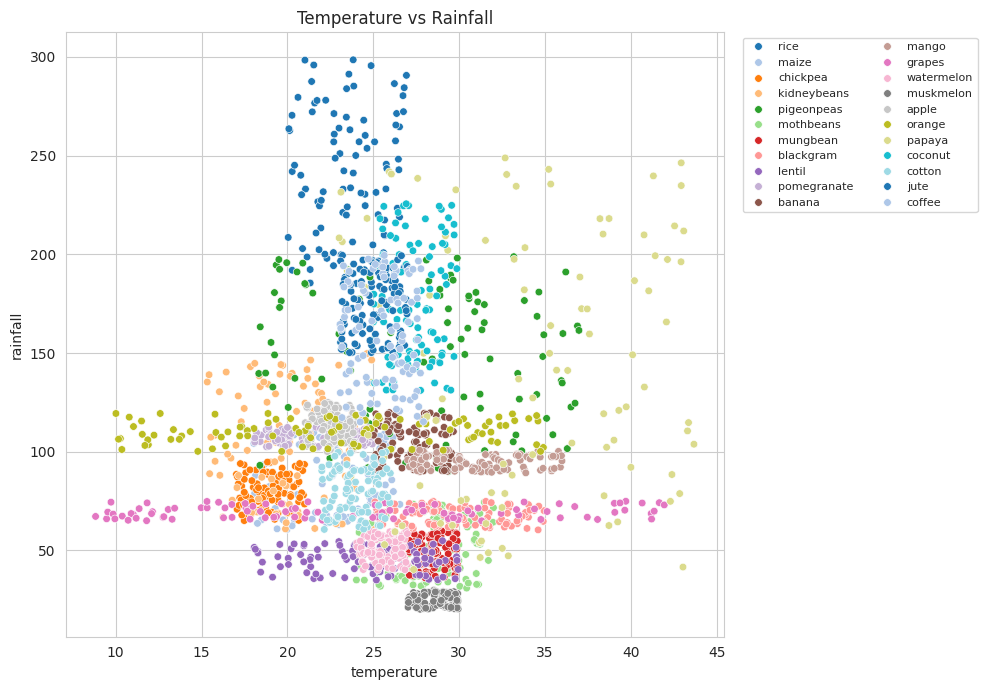

In [10]:
plt.figure(figsize=(10,7))
sns.scatterplot(data=df, x='temperature', y='rainfall', hue='label', palette='tab20', s=30)
plt.legend(bbox_to_anchor=(1.02,1), loc='upper left', ncol=2, fontsize=8)
plt.title('Temperature vs Rainfall'); plt.tight_layout(); plt.show()

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,20.8,134.2,199.9,22.6,92.3,5.9,112.7
banana,100.2,82.0,50.0,27.4,80.4,6.0,104.6
blackgram,40.0,67.5,19.2,30.0,65.1,7.1,67.9
chickpea,40.1,67.8,79.9,18.9,16.9,7.3,80.1
coconut,22.0,16.9,30.6,27.4,94.8,6.0,175.7
coffee,101.2,28.7,29.9,25.5,58.9,6.8,158.1
cotton,117.8,46.2,19.6,24.0,79.8,6.9,80.4
grapes,23.2,132.5,200.1,23.8,81.9,6.0,69.6
jute,78.4,46.9,40.0,25.0,79.6,6.7,174.8


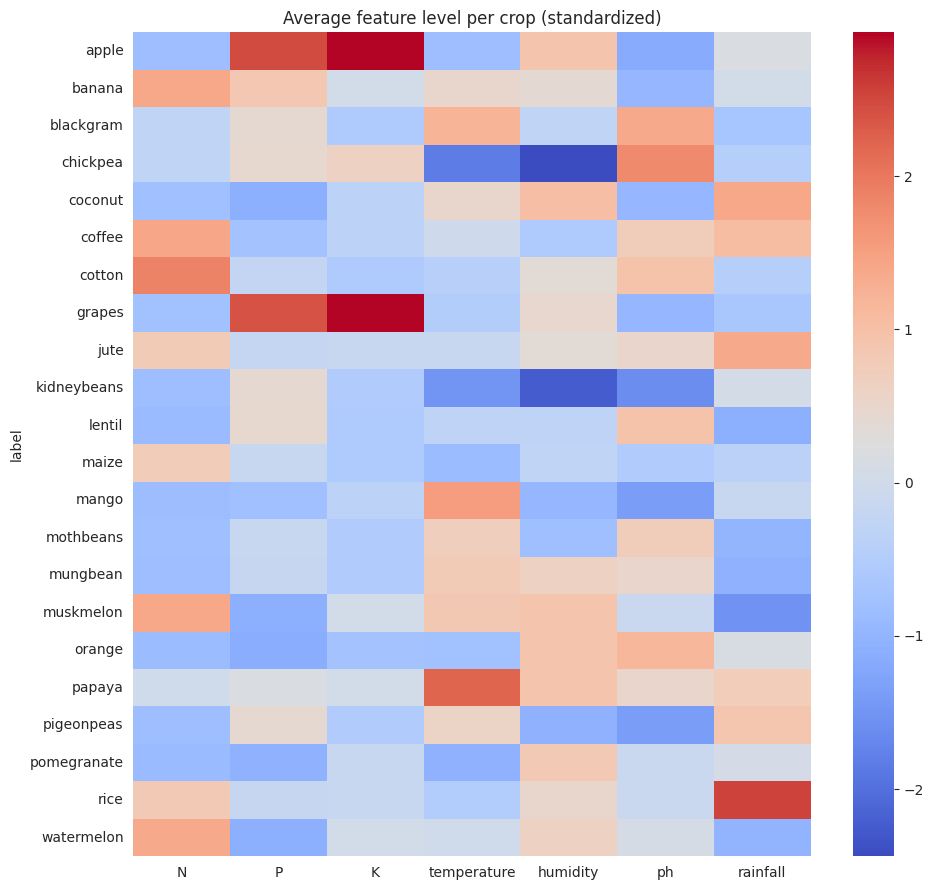

In [11]:
crop_means = df.groupby('label')[features].mean().round(1)
display(crop_means)

plt.figure(figsize=(10,9))
sns.heatmap((crop_means - crop_means.mean())/crop_means.std(), cmap='coolwarm')
plt.title('Average feature level per crop (standardized)')
plt.tight_layout(); plt.show()

In [12]:
for c in features:
    q1, q3 = df[c].quantile([.25,.75]); iqr = q3-q1
    n = ((df[c] < q1-1.5*iqr) | (df[c] > q3+1.5*iqr)).sum()
    print(f"{c:12s} IQR outliers: {n}")

N            IQR outliers: 0
P            IQR outliers: 138
K            IQR outliers: 200
temperature  IQR outliers: 86
humidity     IQR outliers: 30
ph           IQR outliers: 57
rainfall     IQR outliers: 100


In [13]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(df['label'])
X = df[features]
print(dict(zip(le.classes_, le.transform(le.classes_))))


{'apple': np.int64(0), 'banana': np.int64(1), 'blackgram': np.int64(2), 'chickpea': np.int64(3), 'coconut': np.int64(4), 'coffee': np.int64(5), 'cotton': np.int64(6), 'grapes': np.int64(7), 'jute': np.int64(8), 'kidneybeans': np.int64(9), 'lentil': np.int64(10), 'maize': np.int64(11), 'mango': np.int64(12), 'mothbeans': np.int64(13), 'mungbean': np.int64(14), 'muskmelon': np.int64(15), 'orange': np.int64(16), 'papaya': np.int64(17), 'pigeonpeas': np.int64(18), 'pomegranate': np.int64(19), 'rice': np.int64(20), 'watermelon': np.int64(21)}


In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1760, 7)  Test: (440, 7)


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
 'KNN': (Pipeline([('scaler', StandardScaler()), ('m', KNeighborsClassifier())]),
         {'m__n_neighbors': list(range(1, 21)), 'm__weights': ['uniform','distance']}),
 'Decision Tree': (Pipeline([('m', DecisionTreeClassifier(random_state=42))]),
         {'m__max_depth': [3,5,8,12,None], 'm__min_samples_split': [2,5,10],
          'm__criterion': ['gini','entropy']}),
 'SVM': (Pipeline([('scaler', StandardScaler()), ('m', SVC(probability=True, random_state=42))]),
         {'m__C': [0.1,1,10,100], 'm__kernel': ['linear','rbf'], 'm__gamma': ['scale','auto']}),
}

In [17]:
import time
best = {}
for name, (pipe, grid) in models.items():
    t = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring='f1_macro', n_jobs=-1)
    gs.fit(X_train, y_train)
    best[name] = gs
    print(f"{name:14s} CV macro-F1 = {gs.best_score_:.4f} | {gs.best_params_} | {time.time()-t:.1f}s")

KNN            CV macro-F1 = 0.9680 | {'m__n_neighbors': 5, 'm__weights': 'distance'} | 7.2s
Decision Tree  CV macro-F1 = 0.9864 | {'m__criterion': 'gini', 'm__max_depth': 12, 'm__min_samples_split': 5} | 2.2s
SVM            CV macro-F1 = 0.9857 | {'m__C': 10, 'm__gamma': 'scale', 'm__kernel': 'linear'} | 18.1s


In [18]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
rows, preds = [], {}
for name, gs in best.items():
    model = gs.best_estimator_
    p = model.predict(X_test); preds[name] = p
    rows.append({'Model': name,
      'Train Acc': accuracy_score(y_train, model.predict(X_train)),
      'Test Acc': accuracy_score(y_test, p),
      'Precision (macro)': precision_score(y_test, p, average='macro'),
      'Recall (macro)': recall_score(y_test, p, average='macro'),
      'F1 (macro)': f1_score(y_test, p, average='macro')})
results = pd.DataFrame(rows).set_index('Model').round(4)
results

,Train Acc,Test Acc,Precision (macro),Recall (macro),F1 (macro)
Model,,,,,
KNN,1.0000,0.9818,0.9829,0.9818,0.9816
Decision Tree,0.9938,0.9795,0.9810,0.9795,0.9794
SVM,0.9903,0.9886,0.9897,0.9886,0.9886


In [19]:
best_name = results['F1 (macro)'].idxmax()
print("Best model:", best_name)
print(classification_report(y_test, preds[best_name], target_names=le.classes_))

Best model: SVM
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       0.95      1.00      0.98        20
      grapes       1.00      1.00      1.00        20
        jute       0.87      1.00      0.93        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.95      1.00      0.98        20
       maize       1.00      0.95      0.97        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      0.95      0.97        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papay

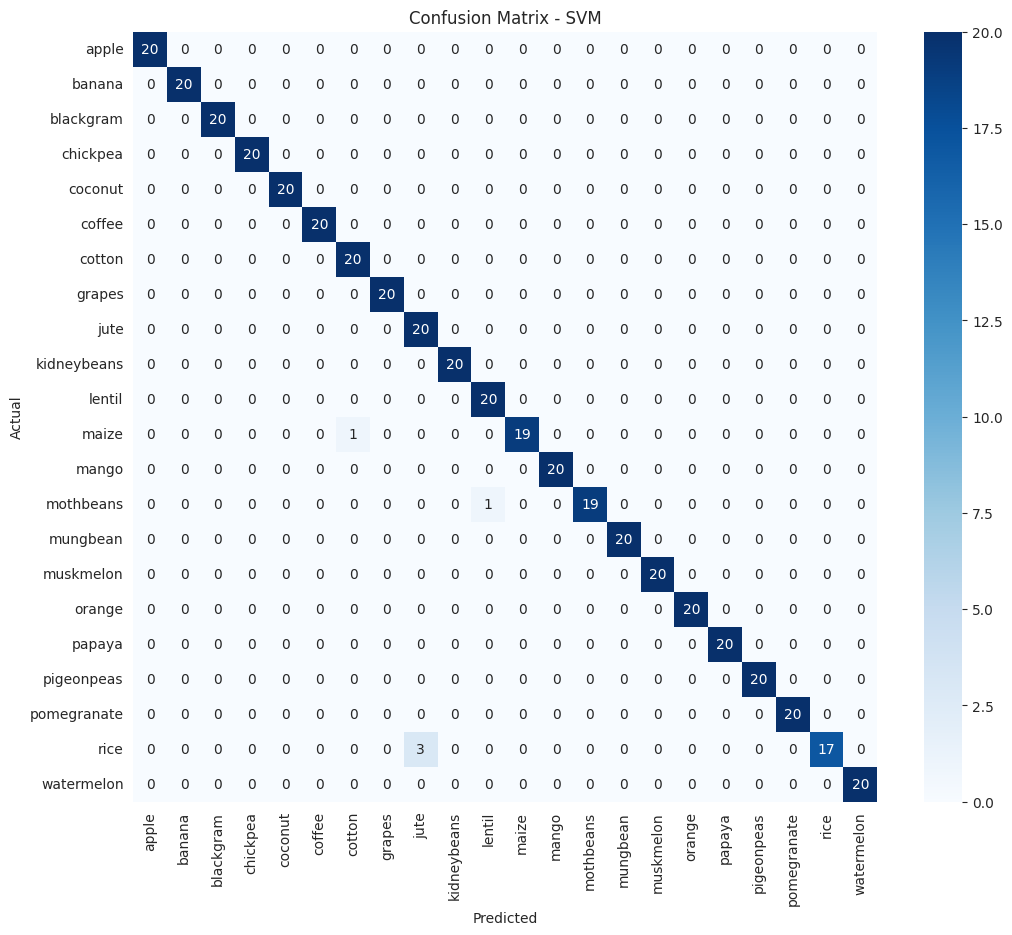

Misclassified (actual, predicted, count): [('maize', 'cotton', 1), ('mothbeans', 'lentil', 1), ('rice', 'jute', 3)]


In [20]:
cm = confusion_matrix(y_test, preds[best_name])
plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Confusion Matrix - {best_name}')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

errs = [(le.classes_[i], le.classes_[j], int(cm[i,j]))
        for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i,j] > 0]
print("Misclassified (actual, predicted, count):", errs)

In [21]:
from sklearn.model_selection import cross_val_score
cv_rows = []
for name, gs in best.items():
    s = cross_val_score(gs.best_estimator_, X, y, cv=cv, scoring='accuracy')
    cv_rows.append({'Model': name, 'CV mean': s.mean(), 'CV std': s.std()})
pd.DataFrame(cv_rows).set_index('Model').round(4)

,CV mean,CV std
Model,,
KNN,0.9755,0.0090
Decision Tree,0.9873,0.0047
SVM,0.9864,0.0014


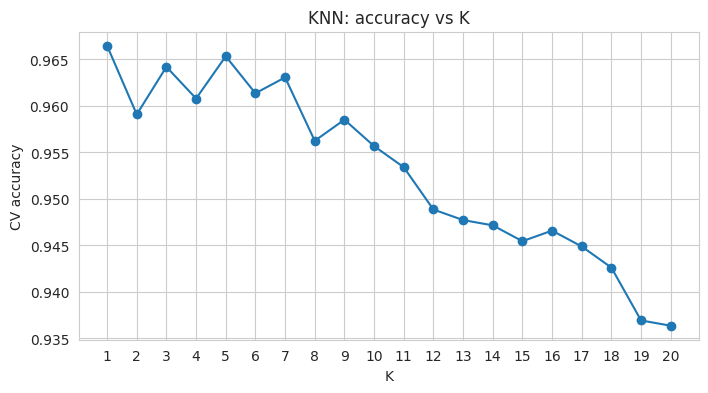

Best K (uniform weights): 1


In [22]:
ks = list(range(1, 21)); k_scores = []
for k in ks:
    pipe = Pipeline([('scaler', StandardScaler()), ('m', KNeighborsClassifier(n_neighbors=k))])
    k_scores.append(cross_val_score(pipe, X_train, y_train, cv=cv).mean())

plt.figure(figsize=(8,4))
plt.plot(ks, k_scores, marker='o'); plt.xticks(ks)
plt.xlabel('K'); plt.ylabel('CV accuracy'); plt.title('KNN: accuracy vs K')
plt.show()
print("Best K (uniform weights):", ks[int(np.argmax(k_scores))])

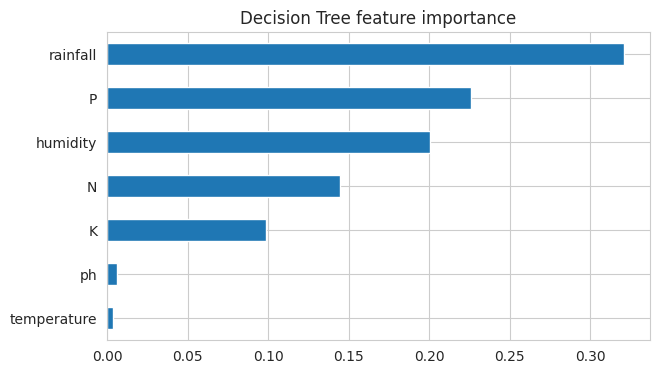

,0
rainfall,0.321
P,0.226
humidity,0.200
N,0.145
K,0.099
ph,0.006
temperature,0.003


In [23]:
dt = best['Decision Tree'].best_estimator_.named_steps['m']
imp = pd.Series(dt.feature_importances_, index=features).sort_values()
imp.plot(kind='barh', figsize=(7,4), title='Decision Tree feature importance')
plt.show()
imp.sort_values(ascending=False).round(3)

,KNN,Decision Tree,SVM
noise=0σ,0.9818,0.9795,0.9886
noise=0.1σ,0.9750,0.9295,0.9818
noise=0.25σ,0.9250,0.7136,0.9091
noise=0.5σ,0.7523,0.4614,0.6682


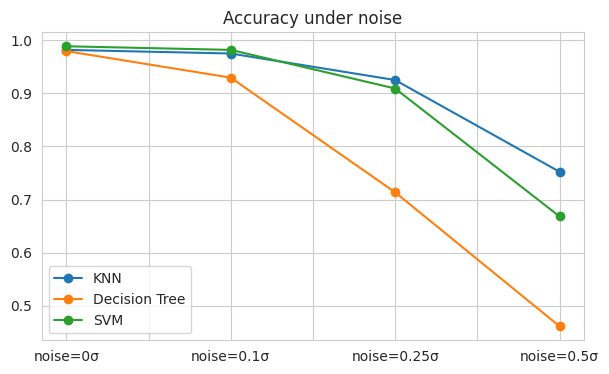

In [24]:
rng = np.random.default_rng(42)
levels = [0, 0.1, 0.25, 0.5]
rob = {}
for name, gs in best.items():
    accs = []
    for lv in levels:
        noise = rng.normal(0, lv, X_test.shape) * X_train.std().values
        accs.append(accuracy_score(y_test, gs.best_estimator_.predict(X_test + noise)))
    rob[name] = accs
rob_df = pd.DataFrame(rob, index=[f'noise={l}σ' for l in levels]).round(4)
display(rob_df)
rob_df.plot(marker='o', figsize=(7,4), title='Accuracy under noise'); plt.show()

In [26]:
def top_k_acc(model, X_, y_, k=3):
    proba = model.predict_proba(X_)
    topk = np.argsort(proba, axis=1)[:, -k:]
    return np.mean([y_[i] in topk[i] for i in range(len(y_))])

for name, gs in best.items():
    print(f"{name:14s} top-3 accuracy: {top_k_acc(gs.best_estimator_, X_test, y_test):.4f}")

KNN            top-3 accuracy: 0.9977
Decision Tree  top-3 accuracy: 0.9841
SVM            top-3 accuracy: 1.0000


In [28]:
final_model = best[best_name].best_estimator_

def recommend_crop(N, P, K, temperature, humidity, ph, rainfall, top=3):
    row = pd.DataFrame([[N, P, K, temperature, humidity, ph, rainfall]], columns=features)
    proba = final_model.predict_proba(row)[0]
    idx = np.argsort(proba)[::-1][:top]
    return [(le.classes_[i], round(float(proba[i])*100, 1)) for i in idx]

print(recommend_crop(90, 42, 43, 25.5, 80, 6.5, 200))

[('rice', 52.0), ('jute', 40.1), ('coffee', 3.0)]


In [29]:
import joblib, os
os.makedirs('model', exist_ok=True)
joblib.dump({'model': final_model, 'encoder': le, 'features': features}, 'model/crop_model.pkl')
print("Saved to model/crop_model.pkl")

Saved to model/crop_model.pkl
